# Chapter 4. Implementation
## 4.3 Total Variation Mapping

The pilot search identifies a suitable range for the TV weight $w$. The weight is then calibrated and three mappings are validated.


## 1. Pilot Range Search

Five calibration images are used for the pilot search. A coarse search identifies the useful weight range for each noise level.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoisers import total_variation_denoise
from src.metrics import calculate_psnr
from src.noise import add_gaussian_noise
from src.utils import load_grayscale_image


In [2]:
# Experiment settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
num_validation = 30
num_pilot = 5

coarse_weight_values = [
    0.001, 0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03,
    0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.18
]

fine_half_width = 0.025
fine_step = 0.0025
minimum_weight = 0.0005
maximum_weight = 0.20

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter4_TV_Calibration"
result_dir.mkdir(parents=True, exist_ok=True)

print("Calibration directory:", calibration_dir)
print("Noise levels (%):", noise_levels)
print("Coarse TV weights:", coarse_weight_values)
print("Fine-search step:", fine_step)
print("Seed:", seed)


Calibration directory: D:\MScProject\data\calibration
Noise levels (%): [2, 4, 6, 8, 10, 12, 15]
Coarse TV weights: [0.001, 0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1, 0.12, 0.15, 0.18]
Fine-search step: 0.0025
Seed: 42


In [3]:
# Find all image files
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(image_files)
required_images = num_calibration + num_validation

if len(image_files) < required_images:
    raise FileNotFoundError(
        f"At least {required_images} images are required, but only {len(image_files)} were found in {calibration_dir}"
    )

# Create reproducible calibration and validation sets
split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
validation_indices = shuffled_indices[num_calibration:required_images]

calibration_files = sorted([image_files[index] for index in calibration_indices])
validation_files = sorted([image_files[index] for index in validation_indices])

# Select five pilot images
pilot_rng = np.random.default_rng(seed)
pilot_indices = pilot_rng.choice(len(calibration_files), size=num_pilot, replace=False)
pilot_files = [calibration_files[index] for index in pilot_indices]
pilot_names = [image_file.stem for image_file in pilot_files]

# Load clean images
calibration_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in calibration_files
}
validation_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in validation_files
}

print("Number of calibration images:", len(calibration_images))
print("Calibration image IDs:")
print(", ".join(image_file.stem for image_file in calibration_files))
print("\nNumber of validation images:", len(validation_images))
print("Validation image IDs:")
print(", ".join(image_file.stem for image_file in validation_files))
print("\nNumber of pilot images:", len(pilot_files))
print("Pilot image IDs:")
print(", ".join(sorted(pilot_names)))


Number of calibration images: 50
Calibration image IDs:
004, 008, 009, 010, 021, 025, 026, 027, 030, 034, 038, 039, 047, 051, 052, 055, 057, 068, 071, 076, 080, 085, 093, 097, 102, 105, 107, 116, 122, 131, 134, 139, 145, 148, 149, 151, 153, 154, 158, 165, 172, 174, 177, 179, 188, 189, 190, 191, 197, 198

Number of validation images: 30
Validation image IDs:
001, 003, 005, 013, 028, 029, 033, 053, 056, 063, 067, 069, 081, 082, 083, 087, 089, 090, 095, 099, 104, 109, 113, 115, 119, 135, 144, 156, 181, 200

Number of pilot images: 5
Pilot image IDs:
021, 085, 139, 153, 198


In [4]:
# Run the coarse TV-weight search on the five pilot images
def evaluate_pilot_candidates(image_name, noise_percent):
    clean_image = calibration_images[image_name]
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    image_results = []

    for weight in coarse_weight_values:
        denoised_image = total_variation_denoise(noisy_image, weight=weight)
        psnr = calculate_psnr(clean_image, denoised_image)
        image_results.append({
            "image": image_name,
            "noise_sigma": noise_percent,
            "weight": weight,
            "psnr": psnr
        })

    return image_results


pilot_outputs = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(evaluate_pilot_candidates)(image_name, noise_percent)
    for noise_percent in noise_levels
    for image_name in pilot_names
)

pilot_results = pd.DataFrame([row for output in pilot_outputs for row in output])
print("Pilot results:", len(pilot_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  12 out of  35 | elapsed:    3.4s remaining:    6.7s
[Parallel(n_jobs=16)]: Done  20 out of  35 | elapsed:    6.3s remaining:    4.7s
[Parallel(n_jobs=16)]: Done  28 out of  35 | elapsed:    6.6s remaining:    1.6s


Pilot results: 560


[Parallel(n_jobs=16)]: Done  35 out of  35 | elapsed:    7.2s finished


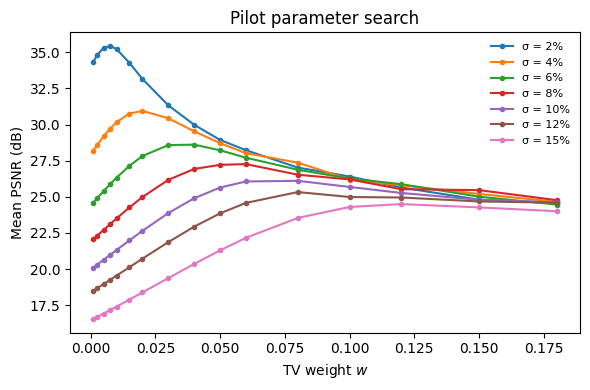

,noise_sigma,weight,psnr
0,2,0.0075,35.435904
1,4,0.0200,30.944449
2,6,0.0400,28.607985
3,8,0.0600,27.260003
4,10,0.0800,26.105336
5,12,0.0800,25.327914
6,15,0.1200,24.495101


,noise_sigma,fine_weight_values
0,2,"0.0005, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0..."
1,4,"0.0005, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0..."
2,6,"0.015, 0.0175, 0.02, 0.0225, 0.025, 0.0275, 0...."
3,8,"0.035, 0.0375, 0.04, 0.0425, 0.045, 0.0475, 0...."
4,10,"0.055, 0.0575, 0.06, 0.0625, 0.065, 0.0675, 0...."
5,12,"0.055, 0.0575, 0.06, 0.0625, 0.065, 0.0675, 0...."
6,15,"0.095, 0.0975, 0.1, 0.1025, 0.105, 0.1075, 0.1..."


In [5]:
# Average the pilot results across images
pilot_mean = pilot_results.groupby(["noise_sigma", "weight"], as_index=False)["psnr"].mean()

# Select the best coarse weight at each noise level
pilot_best_indices = pilot_mean.groupby("noise_sigma")["psnr"].idxmax()
pilot_best_parameters = pilot_mean.loc[pilot_best_indices].sort_values("noise_sigma").reset_index(drop=True)

# Build a fine-search grid around each pilot optimum
fine_weight_values = {}
for _, row in pilot_best_parameters.iterrows():
    noise_percent = int(row["noise_sigma"])
    centre = float(row["weight"])
    lower = max(minimum_weight, centre - fine_half_width)
    upper = min(maximum_weight, centre + fine_half_width)

    first_regular = np.ceil(lower / fine_step) * fine_step
    regular_candidates = np.arange(first_regular, upper + fine_step / 2, fine_step)
    candidates = np.unique(np.round(np.concatenate(([lower, centre], regular_candidates)), 4))
    candidates = candidates[(candidates > 0) & (candidates >= minimum_weight) & (candidates <= maximum_weight)]

    if candidates.size == 0:
        raise ValueError(f"No valid fine-search weights for {noise_percent}% noise.")

    fine_weight_values[noise_percent] = candidates.tolist()
    if np.isclose(centre, min(coarse_weight_values)) or np.isclose(centre, max(coarse_weight_values)):
        print(f"Warning: {noise_percent}% reached a coarse TV-weight boundary.")

fine_range_table = pd.DataFrame({
    "noise_sigma": list(fine_weight_values),
    "fine_weight_values": [", ".join(map(str, values)) for values in fine_weight_values.values()]
})

# Plot the pilot search curves
fig, ax = plt.subplots(figsize=(6, 4))
for noise_percent in noise_levels:
    current = pilot_mean[pilot_mean["noise_sigma"] == noise_percent]
    ax.plot(current["weight"], current["psnr"], marker="o", markersize=3, label=f"σ = {noise_percent}%")

ax.set_xlabel(r"TV weight $w$")
ax.set_ylabel("Mean PSNR (dB)")
ax.set_title("Pilot parameter search")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(result_dir / "tv_pilot_search.png", dpi=300, bbox_inches="tight")
plt.show()

display(pilot_best_parameters)
display(fine_range_table)


## 2. Calibration

The TV weight is fine-tuned at each noise level on all fifty calibration images. The selected values are used to build three mappings.


In [6]:
# Run the fine TV-weight search on all calibration images
for noise_percent, values in fine_weight_values.items():
    if not values or any(weight <= 0 for weight in values):
        raise ValueError(f"Invalid fine-search weights for {noise_percent}%: {values}")


def evaluate_calibration_image(image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    image_results = []

    for weight in fine_weight_values[noise_percent]:
        denoised_image = total_variation_denoise(noisy_image, weight=weight)
        psnr = calculate_psnr(clean_image, denoised_image)
        image_results.append({
            "image": image_name,
            "noise_sigma": noise_percent,
            "seed": seed,
            "weight": weight,
            "psnr": psnr
        })

    return image_results


fine_outputs = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(evaluate_calibration_image)(image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images.items()
)

grid_results = pd.DataFrame([row for output in fine_outputs for row in output])
print("Fine-search results:", len(grid_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    8.0s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   33.3s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:  1.5min


Fine-search results: 6900


[Parallel(n_jobs=16)]: Done 350 out of 350 | elapsed:  2.2min finished


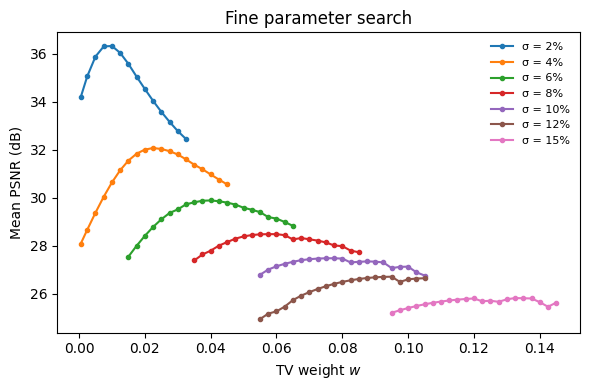

,noise_sigma,weight,psnr
0,2,0.0100,36.329744
1,4,0.0225,32.070485
2,6,0.0400,29.884726
3,8,0.0575,28.477437
4,10,0.0750,27.471250
5,12,0.0950,26.701653
6,15,0.1325,25.811273


In [7]:
# Average PSNR across the fifty calibration images
mean_results = grid_results.groupby(["noise_sigma", "weight"], as_index=False)["psnr"].mean()

# Select the best TV weight at each noise level
best_indices = mean_results.groupby("noise_sigma")["psnr"].idxmax()
best_parameters = mean_results.loc[best_indices].sort_values("noise_sigma").reset_index(drop=True)

# Check fine-search boundaries
for _, row in best_parameters.iterrows():
    noise_percent = int(row["noise_sigma"])
    selected_weight = float(row["weight"])
    current_range = fine_weight_values[noise_percent]
    if np.isclose(selected_weight, min(current_range)) or np.isclose(selected_weight, max(current_range)):
        print(f"Warning: {noise_percent}% reached a fine TV-weight boundary.")

# Plot the fine-search curves
fig, ax = plt.subplots(figsize=(6, 4))
for noise_percent in noise_levels:
    current = mean_results[mean_results["noise_sigma"] == noise_percent]
    ax.plot(current["weight"], current["psnr"], marker="o", markersize=3, label=f"σ = {noise_percent}%")

ax.set_xlabel(r"TV weight $w$")
ax.set_ylabel("Mean PSNR (dB)")
ax.set_title("Fine parameter search")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(result_dir / "tv_fine_search.png", dpi=300, bbox_inches="tight")
plt.show()

best_parameters


Mapping: w = 0.000235σ² +0.005365σ -0.001705
R² = 0.9994


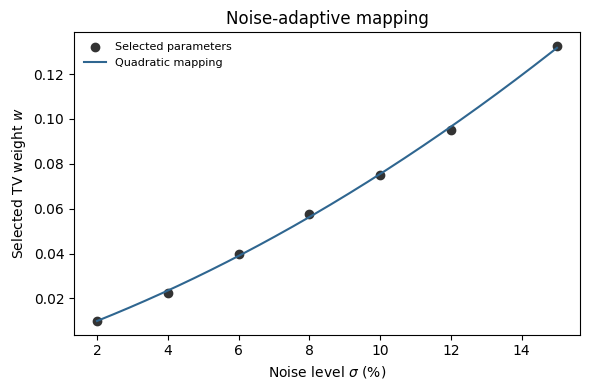

,noise_sigma,weight,psnr
0,2,0.0100,36.329744
1,4,0.0225,32.070485
2,6,0.0400,29.884726
3,8,0.0575,28.477437
4,10,0.0750,27.471250
5,12,0.0950,26.701653
6,15,0.1325,25.811273


,quadratic_coefficient,linear_coefficient,intercept,r_squared,minimum_weight,maximum_weight
0,0.000235,0.005365,-0.001705,0.999372,0.01,0.1325


In [8]:
# Fit a quadratic noise-to-weight mapping
noise_values = best_parameters["noise_sigma"].to_numpy(dtype=float)
weight_values = best_parameters["weight"].to_numpy(dtype=float)
quadratic_coefficients = np.polyfit(noise_values, weight_values, 2)
fitted_values = np.polyval(quadratic_coefficients, noise_values)

residual_sum = np.sum((weight_values - fitted_values) ** 2)
total_sum = np.sum((weight_values - np.mean(weight_values)) ** 2)
r_squared = 1 - residual_sum / total_sum if total_sum > 0 else 0.0

minimum_selected_weight = float(weight_values.min())
maximum_selected_weight = float(weight_values.max())

mapping = pd.DataFrame({
    "quadratic_coefficient": [quadratic_coefficients[0]],
    "linear_coefficient": [quadratic_coefficients[1]],
    "intercept": [quadratic_coefficients[2]],
    "r_squared": [r_squared],
    "minimum_weight": [minimum_selected_weight],
    "maximum_weight": [maximum_selected_weight]
})

print(
    f"Mapping: w = {quadratic_coefficients[0]:.6f}σ² "
    f"{quadratic_coefficients[1]:+.6f}σ {quadratic_coefficients[2]:+.6f}"
)
print(f"R² = {r_squared:.4f}")

# Plot the selected parameters and fitted mapping
fig, ax = plt.subplots(figsize=(6, 4))
plot_noise = np.linspace(min(noise_values), max(noise_values), 200)
plot_weight = np.polyval(quadratic_coefficients, plot_noise)

ax.scatter(noise_values, weight_values, color="#333333", label="Selected parameters")
ax.plot(plot_noise, plot_weight, color="#2F6690", label="Quadratic mapping")
ax.set_xlabel(r"Noise level $\sigma$ (%)")
ax.set_ylabel(r"Selected TV weight $w$")
ax.set_title("Noise-adaptive mapping")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(result_dir / "tv_parameter_mapping.png", dpi=300, bbox_inches="tight")
plt.show()

display(best_parameters)
display(mapping)


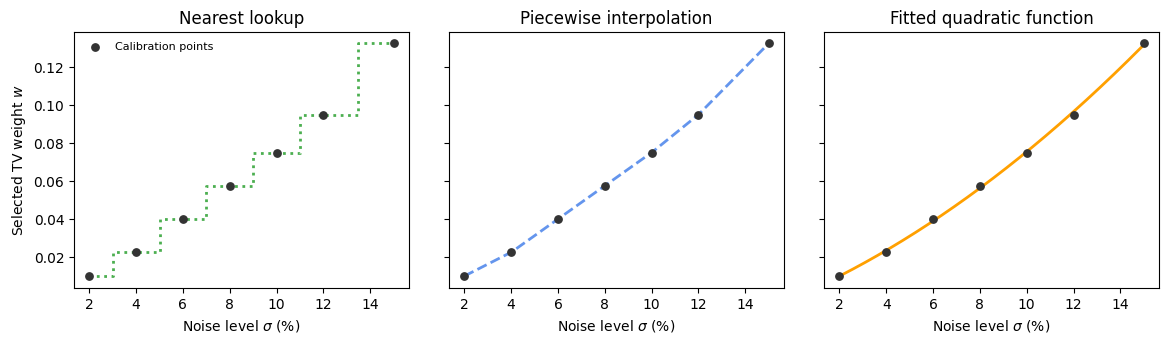

,noise_sigma,lookup_weight,interpolated_weight,fitted_weight
0,2,0.0100,0.01000,0.010000
1,3,0.0100,0.01625,0.016509
2,4,0.0225,0.02250,0.023522
3,5,0.0225,0.03125,0.031005
4,6,0.0400,0.04000,0.038959
5,7,0.0400,0.04875,0.047384
6,8,0.0575,0.05750,0.056279
7,9,0.0575,0.06625,0.065645
8,10,0.0750,0.07500,0.075482
9,11,0.0750,0.08500,0.085789


In [9]:
# Define the three candidate mapping strategies
def select_tv_weight_lookup(estimated_sigma_percent):
    distances = np.abs(noise_values - estimated_sigma_percent)
    nearest_index = int(np.argmin(distances))
    return float(weight_values[nearest_index])


def select_tv_weight_interpolated(estimated_sigma_percent):
    return float(np.interp(estimated_sigma_percent, noise_values, weight_values))


def select_tv_weight_fitted(estimated_sigma_percent):
    weight = np.polyval(quadratic_coefficients, estimated_sigma_percent)
    return float(np.clip(weight, minimum_selected_weight, maximum_selected_weight))


# Add noise levels between the calibration points
intermediate_noise_levels = [3, 5, 7, 9, 11, 13, 14]
validation_noise_levels = sorted(set(noise_levels + intermediate_noise_levels))

mapping_comparison = pd.DataFrame({
    "noise_sigma": validation_noise_levels,
    "lookup_weight": [select_tv_weight_lookup(value) for value in validation_noise_levels],
    "interpolated_weight": [select_tv_weight_interpolated(value) for value in validation_noise_levels],
    "fitted_weight": [select_tv_weight_fitted(value) for value in validation_noise_levels]
})

# Plot lookup, interpolation, and the fitted function
plot_noise = np.linspace(min(noise_values), max(noise_values), 400)
lookup_plot = [select_tv_weight_lookup(value) for value in plot_noise]
interpolated_plot = [select_tv_weight_interpolated(value) for value in plot_noise]
fitted_plot = [select_tv_weight_fitted(value) for value in plot_noise]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
axes[0].scatter(noise_values, weight_values, color="#333333", s=28, label="Calibration points", zorder=4)
axes[0].step(plot_noise, lookup_plot, where="mid", color="#4CAF50", linewidth=2, linestyle=":")
axes[0].set_title("Nearest lookup")

axes[1].scatter(noise_values, weight_values, color="#333333", s=28, zorder=4)
axes[1].plot(plot_noise, interpolated_plot, color="#6495ED", linewidth=2, linestyle="--")
axes[1].set_title("Piecewise interpolation")

axes[2].scatter(noise_values, weight_values, color="#333333", s=28, zorder=4)
axes[2].plot(plot_noise, fitted_plot, color="#FFA000", linewidth=2)
axes[2].set_title("Fitted quadratic function")

for ax in axes:
    ax.set_xlabel(r"Noise level $\sigma$ (%)")

axes[0].set_ylabel(r"Selected TV weight $w$")
axes[0].legend(frameon=False, fontsize=8)
fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.12)
fig.savefig(result_dir / "tv_mapping_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

mapping_comparison


## 3. Validation

The three mappings are evaluated on thirty validation images. Final selection uses the intermediate noise levels, which were not used in calibration.


In [10]:
# Evaluate the three mapping strategies on the validation images
def validate_image(image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    lookup_weight = select_tv_weight_lookup(noise_percent)
    interpolated_weight = select_tv_weight_interpolated(noise_percent)
    fitted_weight = select_tv_weight_fitted(noise_percent)

    lookup_image = total_variation_denoise(noisy_image, weight=lookup_weight)
    interpolated_image = total_variation_denoise(noisy_image, weight=interpolated_weight)
    fitted_image = total_variation_denoise(noisy_image, weight=fitted_weight)

    return {
        "image": image_name,
        "noise_sigma": noise_percent,
        "lookup_weight": lookup_weight,
        "interpolated_weight": interpolated_weight,
        "fitted_weight": fitted_weight,
        "noisy_psnr": calculate_psnr(clean_image, noisy_image),
        "lookup_psnr": calculate_psnr(clean_image, lookup_image),
        "interpolated_psnr": calculate_psnr(clean_image, interpolated_image),
        "fitted_psnr": calculate_psnr(clean_image, fitted_image)
    }


validation_rows = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(validate_image)(image_name, clean_image, noise_percent)
    for noise_percent in validation_noise_levels
    for image_name, clean_image in validation_images.items()
)

validation_results = pd.DataFrame(validation_rows)
validation_summary = validation_results.groupby("noise_sigma", as_index=False)[
    [
        "lookup_weight", "interpolated_weight", "fitted_weight", "noisy_psnr",
        "lookup_psnr", "interpolated_psnr", "fitted_psnr"
    ]
].mean()

# Select the final strategy using only intermediate noise levels
intermediate_results = validation_results[
    validation_results["noise_sigma"].isin(intermediate_noise_levels)
]
mean_noisy_psnr = intermediate_results["noisy_psnr"].mean()

method_rows = []
for method_name, psnr_column in {
    "Nearest lookup": "lookup_psnr",
    "Piecewise interpolation": "interpolated_psnr",
    "Fitted quadratic function": "fitted_psnr"
}.items():
    mean_psnr = intermediate_results[psnr_column].mean()
    method_rows.append({
        "mapping_method": method_name,
        "mean_psnr": mean_psnr,
        "gain_over_noisy": mean_psnr - mean_noisy_psnr
    })

validation_method_summary = (
    pd.DataFrame(method_rows)
    .sort_values("mean_psnr", ascending=False)
    .reset_index(drop=True)
)
selected_mapping_method = validation_method_summary.loc[0, "mapping_method"]

print("Selected mapping method:", selected_mapping_method)
display(validation_summary)
display(validation_method_summary)


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    2.0s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    7.9s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:   17.0s


Selected mapping method: Piecewise interpolation


[Parallel(n_jobs=16)]: Done 420 out of 420 | elapsed:   28.7s finished


,noise_sigma,lookup_weight,interpolated_weight,fitted_weight,noisy_psnr,lookup_psnr,interpolated_psnr,fitted_psnr
0,2,0.0100,0.01000,0.010000,33.945304,36.657115,36.657115,36.657115
1,3,0.0100,0.01625,0.016509,30.423479,33.544850,34.106227,34.105221
2,4,0.0225,0.02250,0.023522,27.924704,32.367316,32.367316,32.414211
3,5,0.0225,0.03125,0.031005,25.986504,30.724127,31.158499,31.172189
4,6,0.0400,0.04000,0.038959,24.402879,30.213163,30.213163,30.209245
5,7,0.0400,0.04875,0.047384,23.063943,29.204041,29.432832,29.428381
6,8,0.0575,0.05750,0.056279,21.904104,28.781945,28.781945,28.778012
7,9,0.0575,0.06625,0.065645,20.881053,28.086465,28.225489,28.223631
8,10,0.0750,0.07500,0.075482,19.965904,27.742166,27.742166,27.743369
9,11,0.0750,0.08500,0.085789,19.138050,27.192193,27.318432,27.318665


,mapping_method,mean_psnr,gain_over_noisy
0,Piecewise interpolation,29.000593,6.968677
1,Fitted quadratic function,28.999332,6.967416
2,Nearest lookup,28.771234,6.739319


In [11]:
# Show validation results at intermediate noise levels
validation_psnr_table = (
    validation_summary[validation_summary["noise_sigma"].isin(intermediate_noise_levels)][
        ["noise_sigma", "lookup_psnr", "interpolated_psnr", "fitted_psnr"]
    ]
    .rename(columns={
        "noise_sigma": "Noise level (%)",
        "lookup_psnr": "Nearest lookup",
        "interpolated_psnr": "Piecewise interpolation",
        "fitted_psnr": "Fitted quadratic function"
    })
    .round(4)
)

mean_row = pd.DataFrame({
    "Noise level (%)": ["Mean"],
    "Nearest lookup": [intermediate_results["lookup_psnr"].mean()],
    "Piecewise interpolation": [intermediate_results["interpolated_psnr"].mean()],
    "Fitted quadratic function": [intermediate_results["fitted_psnr"].mean()]
}).round(4)

validation_psnr_table = pd.concat([validation_psnr_table, mean_row], ignore_index=True)
print("Mean PSNR (dB):")
display(validation_psnr_table)


Mean PSNR (dB):


,Noise level (%),Nearest lookup,Piecewise interpolation,Fitted quadratic function
0,3,33.5448,34.1062,34.1052
1,5,30.7241,31.1585,31.1722
2,7,29.2040,29.4328,29.4284
3,9,28.0865,28.2255,28.2236
4,11,27.1922,27.3184,27.3187
5,13,26.5132,26.5987,26.5369
6,14,26.1337,26.1639,26.2103
7,Mean,28.7712,29.0006,28.9993
